# Monitores secuenciales que mantienen su tamaño leídos cada día

**Pregunta:** Una mesa de validación lee sus backtests cada día y su calibración cada año. Leída así, ¿con qué frecuencia una prueba de
ventana fija rechaza un modelo correcto, puede un monitor leído en cada paso mantener un tamaño de 5 %, y qué cuesta ese tamaño en
demora y en potencia, sobre verdades conocidas y en las ventanas reales de los casos C11 y C03?

- **Nivel:** 4, métodos propuestos
- **Requisitos previos:** los notebooks 01 a 03 de este tema (tamaño, potencia y error de Monte Carlo) y el notebook 03 del tema 07
  (los backtests)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- decir por qué una prueba válida leída una vez pierde su tamaño cuando se lee cada día, y medir cuánto;
- construir a mano el proceso e de una tasa de excepciones del VaR como promedio de apuestas, y leer en él la desigualdad de Ville;
- comparar, en los generadores del caso, el tamaño y la demora de detección del proceso e con la prueba de Kupiec, el semáforo de
  Basilea y la prueba de independencia, leídos como los lee una mesa;
- probar la afirmación del caso contra las reglas escritas antes de la corrida, y leer el monitor en las excepciones reales de C11 y
  las cosechas de C03.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca
instala nada por sí mismo. La celda siguiente importa lo que usa el notebook, pone el pipeline del caso en la ruta e imprime las
versiones.

In [1]:
# Importar las herramientas, poner el pipeline del caso en la ruta e imprimir las versiones con que corren
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.hits import VarHits
from riskvalidation.validation import market as vm
from riskvalidation.validation.sequential import pd_grades, var_hits

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import c22_sequential as seq
from pipeline.cases.c03 import sequential as c03_seq

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres documentos versionados alimentan el notebook. El caso C22 mide las pruebas mismas en generadores de verdad conocida; su documento
de otras familias trae el estudio secuencial: 2.000 series de excepciones de VaR por escenario durante 1.000 días, del generador
`VarHits` del motor, y 2.000 carteras de incumplimientos por grado durante diez años. El caso C11 somete a backtest 18 modelos de VaR
en ventanas reales; el notebook lee los días de excepción al 1 % de cada modelo en la renta variable 2007 a 2009 (504 días) y en el
euro contra el dólar en 2008 (251 días). El caso C03 sigue cosechas de préstamos SBA 7(a); cada documento de cohorte trae, por cosecha,
las curvas acumuladas de incumplimiento predicha y observada entre 12 y 60 meses.

In [2]:
# Leer los documentos versionados: el estudio del caso C22, dos ventanas de C11 y las cinco cohortes de C03
DERIVED = ROOT / "data" / "derived"
block = json.loads((DERIVED / "C22" / "other-families.json").read_text(encoding="utf-8"))["outputs"]["sequential"]
hits_study, pd_study = block["hits"], block["pd_grades"]
c11 = {}
for w in ("equity-2007-09", "fx-2008"):
    c11[w] = json.loads((DERIVED / "C11" / f"{w}.json").read_text(encoding="utf-8"))["outputs"]
c03 = {}
for c in ("fy2006-07", "fy2008-10", "fy2011-14", "fy2015-17", "fy2018-20"):
    c03[c] = json.loads((DERIVED / "C03" / f"{c}.json").read_text(encoding="utf-8"))["outputs"]
print(f"C22: {hits_study['reps']} series x {len(hits_study['scenarios'])} escenarios, "
      f"{hits_study['horizon']} días, seed {block['seed']}")
for w, o in c11.items():
    print(f"C11 {w}: {len(o['grid']['dates'])} días, {len(o['models'])} modelos")
for c, o in c03.items():
    print(f"C03 {c}: {len(o['vintage_curves'])} cosechas, edades (meses) {o['sequential']['months']}")


C22: 2000 series x 7 escenarios, 1000 días, seed 42
C11 equity-2007-09: 504 días, 18 modelos
C11 fx-2008: 251 días, 18 modelos
C03 fy2006-07: 2 cosechas, edades (meses) [12, 24, 36, 48, 60]
C03 fy2008-10: 3 cosechas, edades (meses) [12, 24, 36, 48, 60]
C03 fy2011-14: 4 cosechas, edades (meses) [12, 24, 36, 48, 60]
C03 fy2015-17: 3 cosechas, edades (meses) [12, 24, 36, 48, 60]
C03 fy2018-20: 3 cosechas, edades (meses) [12, 24, 36, 48, 60]


## Método

Una prueba como la de Kupiec es válida cuando se lee una vez, sobre una ventana fijada de antemano: la probabilidad de rechazar un
modelo correcto es entonces su nivel, 5 %. Una mesa no la lee una vez. Lee los últimos 250 días, o todos los días hasta hoy, cada
mañana, y actúa ante el primer rojo. Cada lectura es otra oportunidad de falsa alarma, y en 1.000 mañanas esas oportunidades se
acumulan. La celda siguiente toma un VaR correcto al 1 %, cuyas excepciones son independientes con probabilidad exactamente 1 %, y lo
lee de tres formas: la prueba de Kupiec sobre todos los días hasta hoy, el semáforo de Basilea sobre los últimos 250 días y el proceso
e del motor.

In [3]:
# Un VaR correcto al 1 %: 1.000 días de excepciones a la tasa correcta, leídos cada día por tres reglas
h = VarHits(t=1000, alpha=0.01, with_var=False).draw(np.random.default_rng(8))["hits"]
e = var_hits.var_hit_eprocess(h, 0.01)
days = np.arange(1, 1001)
kupiec_daily = np.array([vm.kupiec_pof(h[:t], 0.01).p_value for t in days])
below = kupiec_daily[49:] < 0.05
first_kupiec = int(np.argmax(below)) + 50 if below.any() else None
light_day, k_min = seq.basel_first_non_green(h[None, :].astype(bool))
print(f"excepciones: {int(h.sum())} | esperadas: 10")
print(f"e-process: max log E {e.log_e.max():.2f} | umbral log 20 {np.log(20):.2f} | rechaza {e.rejected}")
print(f"Kupiec leído cada día: primer día bajo 0,05 {first_kupiec} | días bajo 0,05 {int(below.sum())}")
print(f"semáforo ({k_min} excepciones en 250 días): sale del verde el día {light_day[0]:.0f}")


excepciones: 8 | esperadas: 10
e-process: max log E 2.07 | umbral log 20 3.00 | rechaza False
Kupiec leído cada día: primer día bajo 0,05 192 | días bajo 0,05 422
semáforo (5 excepciones en 250 días): sale del verde el día 817


La serie tiene 8 excepciones en 1.000 días, con 10 esperadas: el modelo no tiene ningún defecto. La prueba de Kupiec sobre todos los
días hasta hoy cae bajo 0,05 por primera vez el día 192 y queda bajo ese valor en 422 de los 951 días en que se lee, y el semáforo, que
pasa a ámbar con 5 excepciones en 250 días, sale de la zona verde el día 817. Una mesa que actuara ante el primer rojo de cualquiera de las dos
reglas habría rechazado este modelo. El proceso e alcanza un log E máximo de 2,07, bajo el umbral log 20 = 3,00, y nunca rechaza.

Un proceso e es una apuesta contra la hipótesis nula. Cada día el monitor apuesta por una tasa de excepciones alternativa
$m\alpha$; la razón de verosimilitud de esa alternativa contra $\alpha$,

$$E_t(m) = \prod_{s \le t} \Big(m^{h_s} \Big(\frac{1 - m\alpha}{1 - \alpha}\Big)^{1 - h_s}\Big),$$

tiene media 1 bajo la nula todos los días, y lo mismo vale para cualquier promedio fijo de tales apuestas. La desigualdad de Ville
acota la probabilidad de que un proceso así alcance alguna vez $1/a$: $P(\sup_t E_t \ge 1/a) \le a$. Rechazar la primera vez que
$E_t \ge 20$ tiene por tanto un tamaño de a lo más 5 %, por seguido que se lea y cuando sea que la mesa se detenga. El motor promedia
ocho apuestas, con $m$ de 0,25 a 10; la celda siguiente construye ese promedio a mano.

In [4]:
# La apuesta a mano: cada tasa alternativa m alfa es una razón de verosimilitud contra alfa; el proceso e es su promedio
grid = np.array([0.25, 0.5, 1.5, 2, 3, 4, 6, 10])
step = np.where(h[:, None] == 1, np.log(grid), np.log((1 - grid * 0.01) / (1 - 0.01)))
log_lr = np.cumsum(step, axis=0)
log_e = np.log(np.exp(log_lr).mean(axis=1))
print(f"el promedio de las apuestas es el proceso e del motor: {np.allclose(log_e, e.log_e)}")
for m, final in zip(grid, log_lr[-1]):
    print(f"m {m:5.2f} | log LR {final:7.2f}")
single = var_hits.var_hit_eprocess(h, 0.01, multipliers=[3.0])
print(f"una apuesta, m = 3: log E {single.log_e[-1]:.2f} | las ocho apuestas: log E {e.log_e[-1]:.2f}")
print(f"valor p válido en todo momento: {e.anytime_p_value:.3f}")


el promedio de las apuestas es el proceso e del motor: True
m  0.25 | log LR   -3.60
m  0.50 | log LR   -0.55
m  1.50 | log LR   -1.78
m  2.00 | log LR   -4.53
m  3.00 | log LR  -11.46
m  4.00 | log LR  -19.44
m  6.00 | log LR  -37.08
m 10.00 | log LR  -76.13
una apuesta, m = 3: log E -11.46 | las ocho apuestas: log E -2.32
valor p válido en todo momento: 0.127


El promedio de las ocho apuestas es el proceso e del motor salvo redondeo. La razón de verosimilitud final de cada apuesta muestra
dónde está la serie: toda apuesta terminó bajo su punto de partida, la más cercana a la verdad (0,5) perdió lo menos, -0,55, y la
apuesta por diez veces la tasa perdió lo más, -76,13. La apuesta única del motor con $m = 3$ da el -11,46 de esa fila, y el promedio de
las ocho termina en un log E de -2,32, un capital de cerca de 0,1. El valor p válido en todo momento, $\min(1, 1/\sup_t E_t)$, es 0,127: válido el
día en que se lea. La figura pone esta serie junto a una cuya tasa de excepciones es el triple de la correcta.

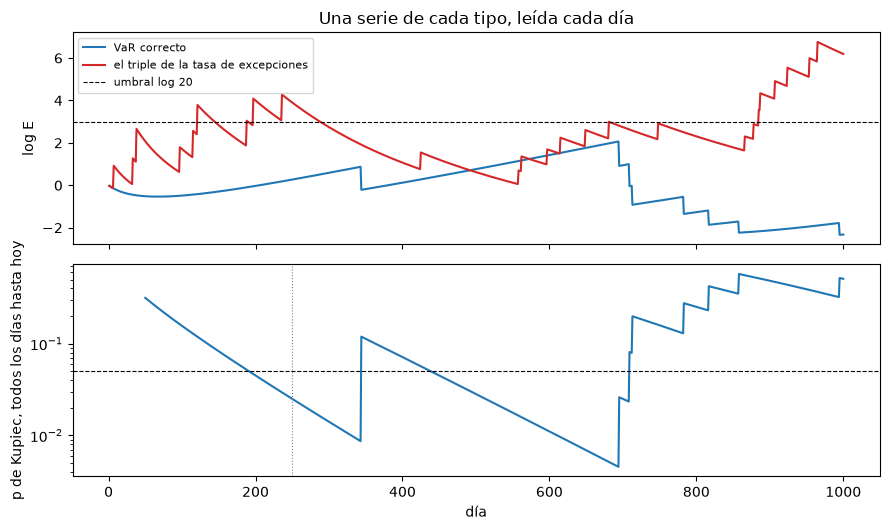

el triple de la tasa de excepciones: excepciones 25 | e-process día 121 | semáforo día 250


In [5]:
# Dibujar log E de la serie correcta y de una con el triple de excepciones, y el p de Kupiec diario
h3 = VarHits(t=1000, alpha=0.01, with_var=False, rate_factor=3.0).draw(np.random.default_rng(7))["hits"]
e3 = var_hits.var_hit_eprocess(h3, 0.01)
light3, _ = seq.basel_first_non_green(h3[None, :].astype(bool))
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True)
top.plot(days, e.log_e, color="tab:blue", label="VaR correcto")
top.plot(days, e3.log_e, color="tab:red", label="el triple de la tasa de excepciones")
top.axhline(np.log(20), color="black", linestyle="--", linewidth=0.8, label="umbral log 20")
top.set_ylabel("log E")
top.set_title("Una serie de cada tipo, leída cada día")
top.legend(fontsize=8)
bottom.plot(days[49:], kupiec_daily[49:], color="tab:blue")
bottom.axhline(0.05, color="black", linestyle="--", linewidth=0.8)
bottom.axvline(250, color="grey", linestyle=":", linewidth=0.8)
bottom.set_yscale("log")
bottom.set_xlabel("día")
bottom.set_ylabel("p de Kupiec, todos los días hasta hoy")
fig.tight_layout()
plt.show()
print(f"el triple de la tasa de excepciones: excepciones {int(h3.sum())} | e-process día {e3.rejection_time} | "
      f"semáforo día {light3[0]:.0f}")


El panel superior es log E. La serie correcta (azul) sube lento mientras escasean las excepciones, hasta 2,07 cerca del día 690, y
cae con cada excepción después, sin llegar al umbral discontinuo; la serie con el triple de excepciones (rojo) lo cruza el día 121,
cerca de seis meses de mercado, mientras el semáforo, que no puede hablar antes de tener 250
días, la marca el día 250. El panel inferior es el valor p de Kupiec sobre todos los días hasta hoy, para la serie correcta, en escala
logarítmica: queda bajo la línea discontinua de 0,05 en dos tramos largos, del día 192 a cerca del día 345 y de cerca del día 440 a
cerca del día 710, con muy pocas excepciones para los días transcurridos. Esa es la falsa alarma que el proceso e
está hecho para evitar.

## Comparación

Los métodos comparados son las pruebas publicadas leídas como las lee una mesa: Kupiec sobre los últimos 250 días y sobre todos los
días hasta hoy, ambas leídas cada día; el semáforo de Basilea, el primer día en que el conteo de excepciones de los últimos 250 días
sale de la zona verde; la prueba de independencia de Christoffersen sobre los últimos 250 días, leída cada día; y, como referencia de
potencia, Kupiec leída una vez sobre los primeros 250 días. Frente a ellas están el proceso e de la tasa, el proceso e de agrupamiento
(una excepción tras otra) y su promedio, la batería. El estudio del caso las corre en el generador `VarHits` del motor: un VaR correcto,
una tasa de excepciones 2, 3 y 4 veces mayor, y excepciones a la tasa correcta que se agrupan. La celda siguiente lo repite con 200
series por escenario; la cifra versionada, entre paréntesis, tiene 2.000.

In [6]:
# Repetir el estudio del caso a un décimo de su tamaño, 200 series por escenario, junto a las 2.000 versionadas
RULES = ("e_rate", "e_battery", "kupiec_trailing", "kupiec_cumulative", "traffic_light", "independence_trailing")
small = seq.run_hits(20261030, reps=200)
print(f"{'':12s} " + " ".join(f"{r[:16]:>17s}" for r in RULES))
for s in small["scenarios"]:
    committed = next(c for c in hits_study["scenarios"] if c["id"] == s["id"])
    print(f"{s['id']:12s} " + " ".join(f"{s[r]['ever']:7.3f} ({committed[r]['ever']:.3f})" for r in RULES))


                        e_rate         e_battery   kupiec_trailing  kupiec_cumulativ     traffic_light  independence_tra
null           0.025 (0.018)   0.000 (0.013)   0.620 (0.665)   0.330 (0.338)   0.570 (0.587)   0.050 (0.076)
rate-x2        0.550 (0.538)   0.445 (0.456)   0.900 (0.869)   0.890 (0.879)   0.975 (0.992)   0.145 (0.155)
rate-x3        0.965 (0.981)   0.960 (0.974)   1.000 (0.998)   1.000 (0.999)   1.000 (1.000)   0.150 (0.152)
rate-x4        1.000 (1.000)   1.000 (0.999)   1.000 (1.000)   1.000 (1.000)   1.000 (1.000)   0.150 (0.170)
cluster-0.1    0.035 (0.046)   0.245 (0.231)   0.785 (0.755)   0.405 (0.395)   0.555 (0.612)   0.555 (0.571)
cluster-0.2    0.105 (0.071)   0.455 (0.508)   0.845 (0.831)   0.540 (0.495)   0.610 (0.615)   0.740 (0.779)
cluster-0.4    0.145 (0.182)   0.805 (0.795)   0.920 (0.951)   0.680 (0.702)   0.690 (0.668)   0.905 (0.920)


Cada entrada es la fracción de series rechazadas algún día de los 1.000, aquí sobre 200 series y entre paréntesis sobre las 2.000
versionadas; ambas coinciden dentro del error de Monte Carlo de 200 series. En un VaR correcto el proceso e versionado rechaza el 1,8 %
de las series y la batería el 1,3 %. Kupiec rechaza el 66,5 % en la ventana móvil y el 33,8 % sobre todos los días hasta hoy, y el
semáforo sale del verde en el 58,7 %. La figura lee las columnas versionadas.

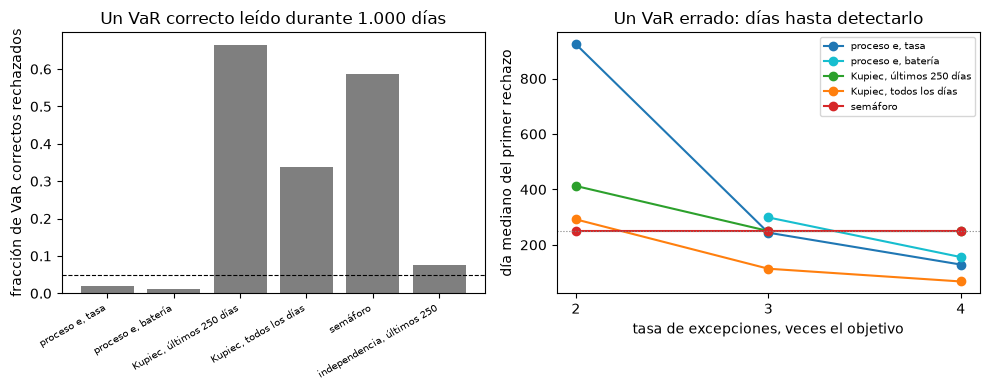

In [7]:
# Dibujar, desde el estudio versionado, cuánto rechaza cada regla un VaR correcto y qué tan rápido detecta uno errado
null = next(s for s in hits_study["scenarios"] if s["id"] == "null")
wrong = [s for s in hits_study["scenarios"] if s["kind"] == "rate"]
names = ["proceso e, tasa", "proceso e, batería", "Kupiec, últimos 250 días",
         "Kupiec, todos los días", "semáforo", "independencia, últimos 250"]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
left.bar(range(len(RULES)), [null[r]["ever"] for r in RULES], color="tab:grey")
left.axhline(0.05, color="black", linestyle="--", linewidth=0.8)
left.set_xticks(range(len(RULES)))
left.set_xticklabels(names, rotation=30, fontsize=7, ha="right")
left.set_ylabel("fracción de VaR correctos rechazados")
left.set_title("Un VaR correcto leído durante 1.000 días")
for r, label, color in zip(RULES[:5], names[:5], ("tab:blue", "tab:cyan", "tab:green", "tab:orange", "tab:red")):
    medians = [s[r]["median_day"] or np.nan for s in wrong]
    right.plot([s["factor"] for s in wrong], medians, "o-", color=color, label=label)
right.axhline(250, color="grey", linestyle=":", linewidth=0.8)
right.set_xticks([2, 3, 4])
right.set_xlabel("tasa de excepciones, veces el objetivo")
right.set_ylabel("día mediano del primer rechazo")
right.set_title("Un VaR errado: días hasta detectarlo")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()


El panel izquierdo es el tamaño: la línea discontinua es 5 %, y solo los dos procesos e y, cerca de ella con 7,6 %, la prueba de
independencia están en torno a ese valor. El panel derecho es el día mediano del primer rechazo con una tasa de excepciones 2, 3 y 4
veces mayor. Kupiec sobre todos los días hasta hoy es la más rápida (114 y 68 días con 3 y 4 veces), pero esa rapidez se paga con el
33,8 % de falsas alarmas del panel izquierdo. El proceso e de la tasa necesita 244 y 129 días; el semáforo y Kupiec en ventana móvil,
250, su primer día posible. La batería, que apuesta también por el agrupamiento, es más lenta: 299 y 156 días.

La misma pregunta vale para una PD. Cinco grados, con PD de 0,5 % a 10 % y 2.000 deudores cada uno por año, se siguen durante diez
años, con cada PD multiplicada por un factor de 1 (un modelo correcto) a 2. El proceso e de incumplimientos por grado combina los
grados por producto (grados independientes) o por promedio (cualquier dependencia); la comparación es la prueba chi-cuadrado entre
grados sobre los conteos acumulados, leída una vez en el año 10 y leída cada año.

In [8]:
# Incumplimientos contra la PD por grado: cinco grados, diez años, cada PD por un factor; 200 carteras aquí
small_pd = seq.run_pd(20261030, reps=200)
for s, committed in zip(small_pd["scenarios"], pd_study["scenarios"]):
    print(f"x{s['factor']:<5g} | e producto {s['e_product']['ever']:.3f} ({committed['e_product']['ever']:.3f}) | "
          f"e promedio {s['e_average']['ever']:.3f} ({committed['e_average']['ever']:.3f}) | "
          f"chi2 una vez en el año 10 {committed['chi2_one_shot_power']:.3f} | "
          f"chi2 cada año {committed['chi2_every_year']['ever']:.3f}")


x1     | e producto 0.000 (0.000) | e promedio 0.000 (0.007) | chi2 una vez en el año 10 0.051 | chi2 cada año 0.201
x1.05  | e producto 0.000 (0.000) | e promedio 0.035 (0.044) | chi2 una vez en el año 10 0.679 | chi2 cada año 0.790
x1.1   | e producto 0.205 (0.247) | e promedio 0.550 (0.600) | chi2 una vez en el año 10 1.000 | chi2 cada año 1.000
x1.25  | e producto 1.000 (1.000) | e promedio 1.000 (1.000) | chi2 una vez en el año 10 1.000 | chi2 cada año 1.000
x1.5   | e producto 1.000 (1.000) | e promedio 1.000 (1.000) | chi2 una vez en el año 10 1.000 | chi2 cada año 1.000
x2     | e producto 1.000 (1.000) | e promedio 1.000 (1.000) | chi2 una vez en el año 10 1.000 | chi2 cada año 1.000


El patrón se repite con un precio mayor. En una PD correcta el proceso e rechaza el 0,0 % (producto) y el 0,7 % (promedio) de las
carteras, donde la chi-cuadrado leída cada año rechaza el 20,1 %. Desde un factor de 1,25 el proceso e detecta todas las carteras, en
dos años. Un error pequeño es donde se paga el tamaño: con un factor de 1,1 la chi-cuadrado única del año 10 detecta todas las
carteras, el proceso e solo el 24,7 % (producto) y el 60,0 % (promedio) en diez años, y con 1,05 la chi-cuadrado detecta el 68 % y el
proceso e a lo más el 4,4 %.

## Evidencia

La afirmación, fijada en el SDD antes de toda corrida, tiene tres partes y una condición de refutación. Tamaño: leído cada día durante
1.000 días, el proceso e rechaza un VaR correcto en a lo más 5 % más tres errores estándar de las series, donde Kupiec repetida
rechaza más. Demora: con una tasa de excepciones 3 y 4 veces mayor, su día mediano de detección está bajo 250 y bajo el del semáforo.
Costo de potencia: una lectura de Kupiec a 250 días tiene menos de 10 puntos más de potencia que el proceso e al día 250. Queda
refutada si la demora no es menor que la del semáforo en las ventanas reales. La celda siguiente aplica las reglas del caso al estudio
versionado.

In [9]:
# Las reglas del veredicto escritas antes de la corrida, recalculadas desde el estudio versionado
v = seq.verdict(hits_study)
h1 = v["H1_size"]
print(f"H1 tamaño: e-process {h1['e_process_size']:.3f} | Kupiec trailing {h1['kupiec_trailing_size']:.3f} | "
      f"Kupiec cumulative {h1['kupiec_cumulative_size']:.3f} | cota {h1['bound']:.4f} | {h1['holds']}")
for sid, d in v["detail"].items():
    print(f"{sid}: día mediano, proceso e / semáforo {d['e_median_day']} / {d['traffic_light_median_day']}")
    print(f"{'':8s}potencia a 250 días, Kupiec / proceso e {d['kupiec_power_250']:.3f} / {d['e_power_by_250']:.3f} | "
          f"costo {d['power_cost']:.3f}")
print(f"H2 {v['H2_delay']['holds']} | H3 {v['H3_power_cost']['holds']} | en conjunto {v['holds']}")
print(block["verdict"]["text"]["es"])


H1 tamaño: e-process 0.018 | Kupiec trailing 0.665 | Kupiec cumulative 0.338 | cota 0.0646 | True
rate-x3: día mediano, proceso e / semáforo 244.0 / 250.0
        potencia a 250 días, Kupiec / proceso e 0.622 / 0.503 | costo 0.119
rate-x4: día mediano, proceso e / semáforo 129.0 / 250.0
        potencia a 250 días, Kupiec / proceso e 0.865 / 0.776 | costo 0.089
H2 True | H3 False | en conjunto False
La hipótesis no se sostiene tal como se planteó: fallaron H3 (H1, H2 se sostuvo). Con una tasa de excepciones 3 veces mayor el proceso e pierde 11,9 puntos de potencia a los 250 días frente a una lectura de Kupiec. Se informa lo medido; los monitores no se reajustaron.


El tamaño se cumple: 1,8 % frente a una cota de 6,5 %, con Kupiec en 66,5 % y 33,8 %. La demora se cumple: días 244 y 129 frente al
250 del semáforo, que es su primer día posible, así que el margen con el triple de la tasa es pequeño. El costo de potencia no se
cumple: una lectura de Kupiec a 250 días tiene 62,2 % de potencia frente a 50,3 % del proceso e con el triple de la tasa, 11,9 puntos
donde la regla permitía 10; con el cuádruple el costo es 8,9 puntos. Así, la afirmación tal como se planteó falla, y se informa de ese
modo; los monitores no se reajustaron. Una salvedad acompaña esa cifra: la lectura única de Kupiec no es aquí una prueba limpia de 5 %,
pues en el estudio versionado rechaza el 10,35 % de las series correctas a 250 días, así que parte de su potencia es tamaño. Siguen las
ventanas reales, con la condición de refutación.

In [10]:
# Las ventanas reales de C11: las excepciones versionadas de cada modelo al 1 %, el proceso e contra el semáforo
real = {}
for w, o in c11.items():
    n_days = len(o["grid"]["dates"])
    for m in o["models"]:
        lvl = next(b for b in m["by_level"] if b["alpha"] == 0.01)
        flags = np.zeros(n_days, bool)
        flags[lvl["exceedance_days"]] = True
        e_day = var_hits.var_hit_eprocess(flags, 0.01).rejection_time
        light, _ = seq.basel_first_non_green(flags[None, :])
        real[(w, m["model_id"])] = (int(flags.sum()), e_day, light[0])
for w in c11:
    rows = [r for (win, _), r in real.items() if win == w]
    e_days = [d for _, d, _ in rows if d is not None]
    light_days = [d for _, _, d in rows if np.isfinite(d)]
    print(f"{w}: {len(rows)} modelos | e-process {len(e_days)}, día mediano {np.median(e_days):.0f} | "
          f"semáforo {len(light_days)}, día mediano {np.median(light_days):.0f}")
missed = [m for (w, m), (_, d, light) in real.items() if w == "fx-2008" and d is None and np.isfinite(light)]
print(f"fx-2008, marcados por el semáforo y no por el proceso e: {missed}")


equity-2007-09: 18 modelos | e-process 18, día mediano 24 | semáforo 18, día mediano 250
fx-2008: 18 modelos | e-process 9, día mediano 68 | semáforo 11, día mediano 250
fx-2008, marcados por el semáforo y no por el proceso e: ['caviar-sav', 'caviar-es']


En la renta variable 2007 a 2009 ambas reglas marcan a los 18 modelos, el proceso e en un día mediano de 24 y el semáforo en el día
250, el primero en que puede hablar; la condición de refutación no ocurre. En el euro en 2008 el proceso e marca 9 modelos en un día
mediano de 68, el semáforo 11 en el día 250; los dos que el proceso e no marca, `caviar-sav` y `caviar-es`, tienen 5 excepciones en
251 días, justo el umbral ámbar, evidencia insuficiente para una apuesta de 20 a 1. La comparación favorece al proceso e por
construcción, porque el semáforo no lee nada antes del día 250; la comparación justa de demora es el estudio con generador de arriba.
La figura muestra la ventana 2007 a 2009.

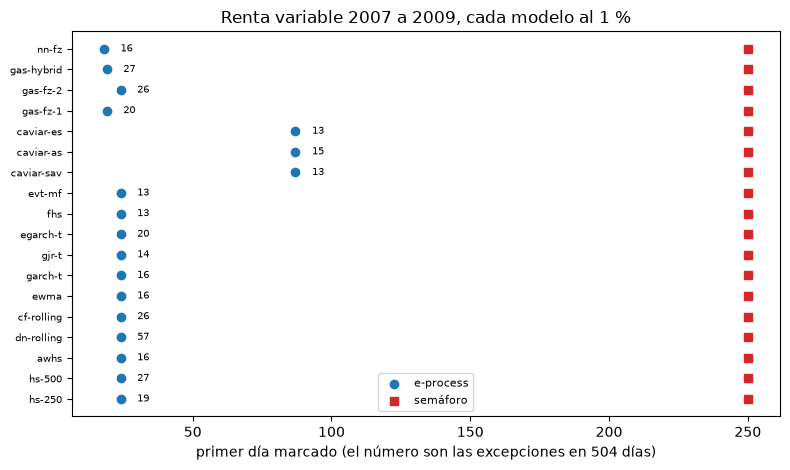

In [11]:
# Dibujar el primer día en que se marca cada modelo de equity-2007-09, por el proceso e y por el semáforo
models = [m for (w, m) in real if w == "equity-2007-09"]
y_pos = np.arange(len(models))
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter([real[("equity-2007-09", m)][1] for m in models], y_pos, color="tab:blue", label="e-process", zorder=3)
ax.scatter([real[("equity-2007-09", m)][2] for m in models], y_pos, color="tab:red", marker="s", label="semáforo")
for i, m in enumerate(models):
    ax.annotate(str(real[("equity-2007-09", m)][0]), (real[("equity-2007-09", m)][1] + 6, i), fontsize=7, va="center")
ax.set_yticks(y_pos)
ax.set_yticklabels(models, fontsize=7)
ax.set_xlabel("primer día marcado (el número son las excepciones en 504 días)")
ax.set_title("Renta variable 2007 a 2009, cada modelo al 1 %")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


Cada fila es un modelo, con su número de excepciones en 504 días junto al punto azul. Los cuadrados rojos forman una columna en el
día 250, porque todo modelo ya tiene más de 4 excepciones cuando el semáforo lee por primera vez. Los puntos azules están entre los
días 18 y 24 para la mayoría de los modelos, las excepciones de julio y agosto de 2007, y en el día 87 para los tres modelos CAViaR,
cuyas primeras excepciones llegaron después. Una mesa que leyera el proceso e habría tenido su respuesta en el primer mes de la crisis
en vez de después de un año.

La última lectura es una calibración. En C03 las cosechas de una cohorte son los grados del proceso e y las edades de 12 a 60 meses
son sus pasos; el monitor apuesta a que los incumplimientos observados de cada edad superan a los predichos (la dirección superior, el
caso que se le paga encontrar a un validador), y promedia las cosechas porque comparten la misma economía.

fy2006-07: primer rechazo (meses) 12 | max log E 11631.0 | semáforos a 5 años ['red', 'red']
fy2008-10: primer rechazo (meses) 12 | max log E 6362.5 | semáforos a 5 años ['red', 'red', 'green']
fy2011-14: primer rechazo (meses) None | max log E -2.5 | semáforos a 5 años ['green', 'green', 'green', 'green']
fy2015-17: primer rechazo (meses) None | max log E -7.3 | semáforos a 5 años ['green', 'green', 'green']
fy2018-20: primer rechazo (meses) None | max log E 2.4 | semáforos a 5 años ['green', 'green', 'green']


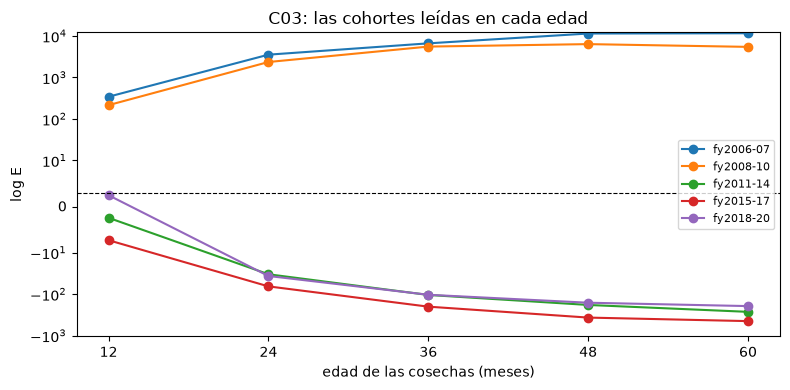

In [12]:
# C03: las cosechas de cada cohorte como grados y las edades como pasos; el proceso e desde las curvas versionadas
fig, ax = plt.subplots(figsize=(8, 4))
for c, o in c03.items():
    parts = [c03_seq.interval_counts(curve) for curve in o["vintage_curves"]]
    d, n, p = (np.stack([q[i] for q in parts], axis=1) for i in range(3))
    res = pd_grades.pd_grade_eprocess(d, n, p, direction="upper", combine="average")
    months = o["sequential"]["months"]
    month = None if res.rejection_time is None else months[res.rejection_time - 1]
    lights = [v["five_year_light"] for v in o["sequential"]["vintages"]]
    print(f"{c}: primer rechazo (meses) {month} | max log E {res.log_e.max():.1f} | semáforos a 5 años {lights}")
    ax.plot(months, res.log_e, "o-", label=c)
ax.axhline(np.log(20), color="black", linestyle="--", linewidth=0.8)
ax.set_yscale("symlog", linthresh=10)
ax.set_xticks([12, 24, 36, 48, 60])
ax.set_xlabel("edad de las cosechas (meses)")
ax.set_ylabel("log E")
ax.set_title("C03: las cohortes leídas en cada edad")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


Las cohortes de 2006 a 2007 y de 2008 a 2010, que enfrentaron la crisis, se rechazan en la primera edad, 12 meses, 48 meses antes
de la lectura fija a cinco años que puso rojo el semáforo binomial de las cosechas 2006 a 2009; su log E llega a 11.631 y 6.363. Las cohortes de 2011 a 2014 y de
2015 a 2017, que el modelo sobrestima, caen muy bajo cero y nunca se rechazan, y la cohorte de 2018 a 2020 sube a 2,4 a los 12 meses,
bajo el umbral de 3,0, y luego cae: su cosecha 2018 sola cruza a los 12 meses, el promedio de las tres no. La nula de este monitor es
una binomial sin correlación de activos, como la prueba binomial vecina, así que un rechazo dice que los conteos son demasiado altos
para incumplimientos independientes, no que el modelo yerre en esa magnitud.

## Resultados

**Respuesta:** Leída cada día durante 1.000 días, Kupiec rechaza un VaR correcto en el 66,5 % de las series con ventana móvil y en el
33,8 % sobre todos los días hasta hoy, y el semáforo sale del verde en el 58,7 %; el proceso e rechaza el 1,8 %. Detecta una tasa de
excepciones 3 y 4 veces mayor en una mediana de 244 y 129 días, y en las excepciones reales de la renta variable 2007 a 2009 marca a
los 18 modelos en una mediana del día 24. El precio es la potencia: con el triple de la tasa pierde 11,9 puntos frente a una lectura de
Kupiec a 250 días, sobre los 10 permitidos, así que la afirmación tal como se planteó no se cumple, y un error de 10 % en la PD se
detecta en a lo más el 60,0 % de las carteras donde una sola chi-cuadrado en el año 10 las detecta todas.

## Resumen

- Una prueba válida leída una vez pierde su tamaño leída cada día; en 1.000 días un VaR correcto falla Kupiec hasta en el 66,5 % de las
  series.
- Un proceso e es un promedio de apuestas de media 1 bajo la nula, y la desigualdad de Ville mantiene su tamaño en 5 % en cualquier
  momento de parada; el tamaño medido es 1,8 %.
- Lee antes que el semáforo de 250 días en excepciones reales (día mediano 24 en 2007 a 2009) y no marca dos modelos con 5 excepciones
  en el euro en 2008.
- El costo es potencia a horizonte fijo, 11,9 puntos con el triple de la tasa, que incumple la regla fijada antes de la corrida, y más
  para un error pequeño de PD.

## Referencias

- Ramdas, A., Grunwald, P., Vovk, V. y Shafer, G. (2023), Game-theoretic statistics and safe anytime-valid inference, Statistical Science 38(4). https://arxiv.org/abs/2210.01948
- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Comité de Basilea de Supervisión Bancaria (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- riskvalidation 1.1.0, `validation.sequential` y su página. https://github.com/fsantibanezleal/CAOS_RiskValidation/blob/main/docs/sequential/README.md